In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd




# Set up a global random number generator
rng = np.random.default_rng(100)

# Function that estimates probability of a purchase given a price
def purchase_probability(price):

    # Turns the input 'price' from an integer into an array scalar
    price = np.asarray(price, dtype=float)

    # Calculate probability of a purchase given a price using 
    # some sales formula we don't need to understand or change.
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )





# Function that calculates sales amount. 
# Default parameters are set but can be changed. 

# Overall, it takes price and mean_customers and generates a random sample of 
# n customers and records whether each customer bought something or not based
# on a generated probability. 
def sales(price=14.0, rng=None, mean_customers=30):

    # Convert price input into a float object. 
    price = float(price)

    # Just a check to make sure the inputs work with the function.
    # Otherwise the function will return the statements "price must be ..."
    # Inputs must be finite and positive or the function won't run.
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")

    # Convert mean_customers input into a float
    mean_customers = float(mean_customers)

    # Check if mean_customers input is finite and positive. 
    # If not, function will not run and will return "mean_customers must be ..."
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")

    # Use the saved 'rng' variable from earlier to save another random 
    # number generator in the function so it is local to the function 
    # instead of just global. 
    rng = np.random.default_rng(rng)

    # Use the mean_customers input to randomly generate a number from the poisson distribution. 
    # This number estimates a customer count from a population of customer counts with a mean of mean_customers. 
    customer_count = rng.poisson(mean_customers)

    # Use the purchase_probability function created earlier.
    probability = purchase_probability(price)

    # Generate 'customer_count' number of trials with one binomial outcome with a 'probability' chance of success.
    # Each element records whether a customer bought something (success) or not (failure) with p = 'probability'
    # One outcome for each customer.
    # 'probability' was generated in the previous line of code.
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

# I think the most confusing part of this function is why the mean_customers and 
# the final customer count is different, but I guess the sample size is 
# also considered random in this scenario and we can't manually set it here. 

In [3]:
# Function that tells us whether to increase or decrease 'price'
def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    
    # Just a check to make sure the inputs are the right kind. 
    # The 'step' input has to be positive. 
    if step <= 0:
        raise ValueError("step must be positive")

    # Set up a local random number generator using the global rng
    rng = np.random.default_rng(rng)

    # np.clip() make sure the 'price' input is contained within [0, 75]
    # If 'price' is any number greater than 75 then it will convert it to 75.
    price = float(np.clip(price, 0, 75))

    # Assigns the whatever highest value is between 0 and 'price'-'step' ends up being.
    # This variable sets up the lower bound of the price range
    price_low = max(0, price - step)

    # Assigns the whatever lowest value is between 'price'+'step' and 75 ends up being.
    # This variable sets up the upper bound of the price range
    price_high = min(75, price + step)



    # Calculates revenue based on the formula from the very start of the lab
    # R(price) = price * sales(price) for both the lower price and the higher price
    # The ouput will be the same length as the 'customer_count' generated in sales().

    # The sample for both the high and low prices will be different because
    # 'customer_count' is generated randomly each time the sales() function is used.

    # This means the number of customers in the low group may be different from the 
    # number of customers in the high group, even though they both use the same 'mean_customers'
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)

    # Checks to make sure the 'customer_count' generated from sales() is greater than 2
    # for both the low price group and the high price group. 
    # If there are less than 2 customers in one group, we have to reset the 'mean_customers'
    # input to a higher number.
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    # Calculate the difference in the mean revenue of both low and high price groups. 
    # This output is one number.
    difference = high.mean() - low.mean()

    # Calculate the standard error of the low and high groups combined
    # using the formula for standard error in the lab. 
    # We use th standard error to calculate confidence intervals. 
    # 'ddof' stands for delta degrees of freedom, which we don't need to worry about.
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))

    # Calculate the range of the highest price and lowest price based
    # on the specified price we input and the step size we input. 
    gap = price_high - price_low

    # Return a dictionary of all the values calculated.
    # (From the lab about the 'gradient' output): 
    # "A positive slope suggests raising the price; 
    # a negative slope suggests lowering it."
    return {
        "price": price,
        "gradient": difference / gap, 
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high), #total customer_count from each group
    }


In [4]:
# Function that records each gradient estimate for a specified number of iterations
def gradient_ascent(start_price, *, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    """Use a fixed experiment budget and a decreasing learning rate."""

    # Just a check to see if 'iterations' input is 1 or more. 
    if iterations < 1:
        raise ValueError("iterations must be at least 1")

    # Set up a local random number generator with 'seed' as a function parameter/input
    # 'seed' can be set to anything, earlier it was set to 100 for us. It just helps
    # replicate the same randomness. 
    search_rng = np.random.default_rng(seed)

    # Ensures price is contained between [0, 75]. If it is higher than 75, it will
    # be turned into 75.
    price = float(np.clip(start_price, 0, 75))

    # Set up empty list for records
    records = []

    # For loop of iterations.
    # In each iteration, calculate and store as dataframe:
    # - the gradient direction for price, and all the other values associated with the estimate_gradient() function
    #    - (price, gradient, gradient_se, ci_low, ci_high, customers)
    # - rate: update the learning rate based on which iteration we are on
    # - move: contain the step to the next price within -2 and 2
    # - next_price: the best price to switch to 
    # - price: set up updated price for the next iteration
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step,
                                     mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

In [5]:
gradient_ascent(start_price = 30, iterations=80, step=1.0, learning_rate=2.0, mean_customers=100, seed=100)

,iteration,price,gradient,gradient_se,ci_low,ci_high,customers,learning_rate,next_price
0,1,30.000000,-0.685936,0.989285,-2.313309,0.941438,219,2.000000,28.628128
1,2,28.628128,-0.311565,0.981034,-1.925366,1.302236,210,1.414214,28.187509
2,3,28.187509,-0.762872,0.978606,-2.372680,0.846935,199,1.154701,27.306620
3,4,27.306620,1.165264,0.958252,-0.411061,2.741589,206,1.000000,28.471884
4,5,28.471884,-0.265553,0.926618,-1.789839,1.258734,228,0.894427,28.234366
...,...,...,...,...,...,...,...,...,...
75,76,27.183370,-1.973659,0.910996,-3.472248,-0.475070,207,0.229416,26.730582
76,77,26.730582,0.444130,0.969080,-1.150007,2.038267,194,0.227921,26.831808
77,78,26.831808,0.050112,0.961839,-1.532112,1.632337,196,0.226455,26.843156
78,79,26.843156,-0.862317,0.963827,-2.447813,0.723179,199,0.225018,26.649120


/var/folders/9z/540dspmj1j31q6xfjkl6q6gm0000gn/T/ipykernel_19234/4273375020.py:27: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(revenue_H, fill=True, label=f"Price H = {p_H}")


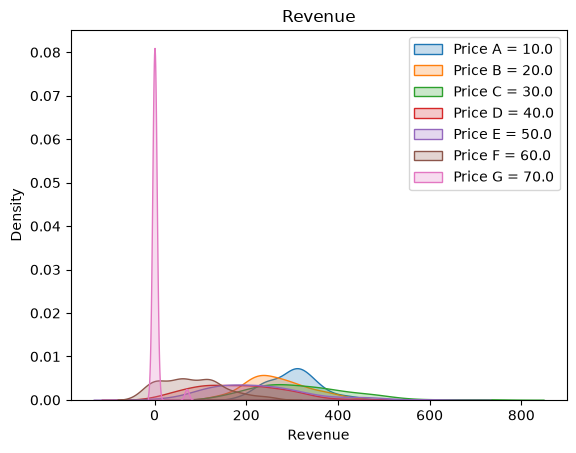

In [6]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 20.0
p_C = 30.0
p_D = 40.0
p_E = 50.0
p_F = 60.0
p_G = 70.0
p_H = 75.0

revenue_A = [ sales(p_A, rng=rng).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng).sum() * p_B for t in range(R) ]
revenue_C = [ sales(p_C, rng=rng).sum() * p_C for t in range(R) ]
revenue_D = [ sales(p_D, rng=rng).sum() * p_D for t in range(R) ]
revenue_E = [ sales(p_E, rng=rng).sum() * p_E for t in range(R) ]
revenue_F = [ sales(p_F, rng=rng).sum() * p_F for t in range(R) ]
revenue_G = [ sales(p_G, rng=rng).sum() * p_G for t in range(R) ]
revenue_H = [ sales(p_H, rng=rng).sum() * p_H for t in range(R) ]

sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
sns.kdeplot(revenue_C, fill=True, label=f"Price C = {p_C}")
sns.kdeplot(revenue_D, fill=True, label=f"Price D = {p_D}")
sns.kdeplot(revenue_E, fill=True, label=f"Price E = {p_E}")
sns.kdeplot(revenue_F, fill=True, label=f"Price F = {p_F}")
sns.kdeplot(revenue_G, fill=True, label=f"Price G = {p_G}")
sns.kdeplot(revenue_H, fill=True, label=f"Price H = {p_H}")

plt.legend()

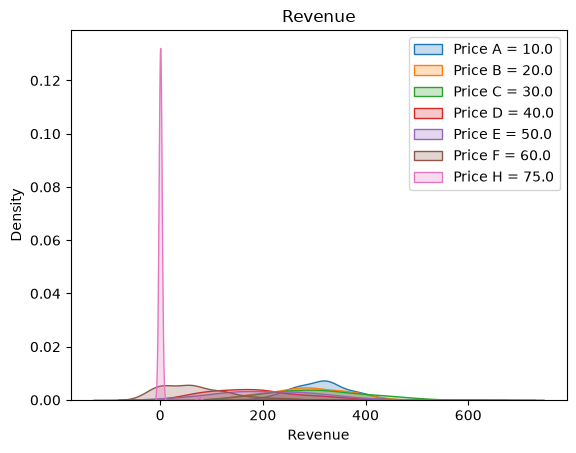

In [7]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 20.0
p_C = 30.0
p_D = 40.0
p_E = 50.0
p_F = 60.0
#p_G = 70.0
p_H = 75.0

revenue_A = [ sales(p_A, rng=rng).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng).sum() * p_B for t in range(R) ]
revenue_C = [ sales(p_C, rng=rng).sum() * p_C for t in range(R) ]
revenue_D = [ sales(p_D, rng=rng).sum() * p_D for t in range(R) ]
revenue_E = [ sales(p_E, rng=rng).sum() * p_E for t in range(R) ]
revenue_F = [ sales(p_F, rng=rng).sum() * p_F for t in range(R) ]
#revenue_G = [ sales(p_G, rng=rng).sum() * p_G for t in range(R) ]
revenue_H = [ sales(p_H, rng=rng).sum() * p_H for t in range(R) ]

sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
sns.kdeplot(revenue_C, fill=True, label=f"Price C = {p_C}")
sns.kdeplot(revenue_D, fill=True, label=f"Price D = {p_D}")
sns.kdeplot(revenue_E, fill=True, label=f"Price E = {p_E}")
sns.kdeplot(revenue_F, fill=True, label=f"Price F = {p_F}")
#sns.kdeplot(revenue_G, fill=True, label=f"Price G = {p_G}")
sns.kdeplot(revenue_H, fill=True, label=f"Price H = {p_H}")

plt.legend()

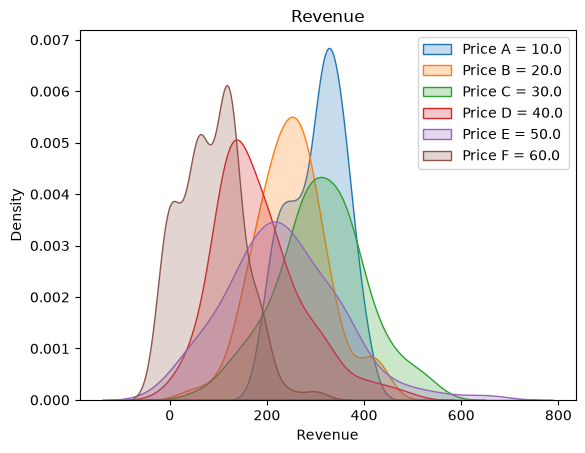

In [ ]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 20.0
p_C = 30.0
p_D = 40.0
p_E = 50.0
p_F = 60.0
#p_G = 70.0
#p_H = 75.0

revenue_A = [ sales(p_A, mean_customers=500, rng=rng).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng).sum() * p_B for t in range(R) ]
revenue_C = [ sales(p_C, rng=rng).sum() * p_C for t in range(R) ]
revenue_D = [ sales(p_D, rng=rng).sum() * p_D for t in range(R) ]
revenue_E = [ sales(p_E, rng=rng).sum() * p_E for t in range(R) ]
revenue_F = [ sales(p_F, rng=rng).sum() * p_F for t in range(R) ]
#revenue_G = [ sales(p_G, rng=rng).sum() * p_G for t in range(R) ]
#revenue_H = [ sales(p_H, rng=rng).sum() * p_H for t in range(R) ]

sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
sns.kdeplot(revenue_C, fill=True, label=f"Price C = {p_C}")
sns.kdeplot(revenue_D, fill=True, label=f"Price D = {p_D}")
sns.kdeplot(revenue_E, fill=True, label=f"Price E = {p_E}")
sns.kdeplot(revenue_F, fill=True, label=f"Price F = {p_F}")
#sns.kdeplot(revenue_G, fill=True, label=f"Price G = {p_G}")
#sns.kdeplot(revenue_H, fill=True, label=f"Price H = {p_H}")

plt.legend()

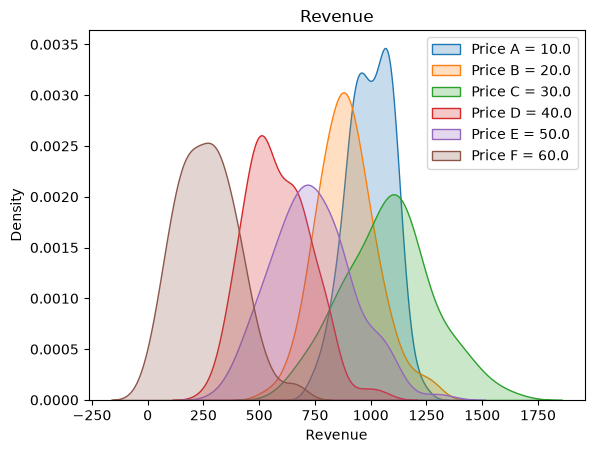

In [9]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 20.0
p_C = 30.0
p_D = 40.0
p_E = 50.0
p_F = 60.0
#p_G = 70.0
#p_H = 75.0

revenue_A = [ sales(p_A, rng=rng, mean_customers=100).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng, mean_customers=100).sum() * p_B for t in range(R) ]
revenue_C = [ sales(p_C, rng=rng, mean_customers=100).sum() * p_C for t in range(R) ]
revenue_D = [ sales(p_D, rng=rng, mean_customers=100).sum() * p_D for t in range(R) ]
revenue_E = [ sales(p_E, rng=rng, mean_customers=100).sum() * p_E for t in range(R) ]
revenue_F = [ sales(p_F, rng=rng, mean_customers=100).sum() * p_F for t in range(R) ]
#revenue_G = [ sales(p_G, rng=rng).sum() * p_G for t in range(R) ]
#revenue_H = [ sales(p_H, rng=rng).sum() * p_H for t in range(R) ]

sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
sns.kdeplot(revenue_C, fill=True, label=f"Price C = {p_C}")
sns.kdeplot(revenue_D, fill=True, label=f"Price D = {p_D}")
sns.kdeplot(revenue_E, fill=True, label=f"Price E = {p_E}")
sns.kdeplot(revenue_F, fill=True, label=f"Price F = {p_F}")
#sns.kdeplot(revenue_G, fill=True, label=f"Price G = {p_G}")
#sns.kdeplot(revenue_H, fill=True, label=f"Price H = {p_H}")

plt.legend()

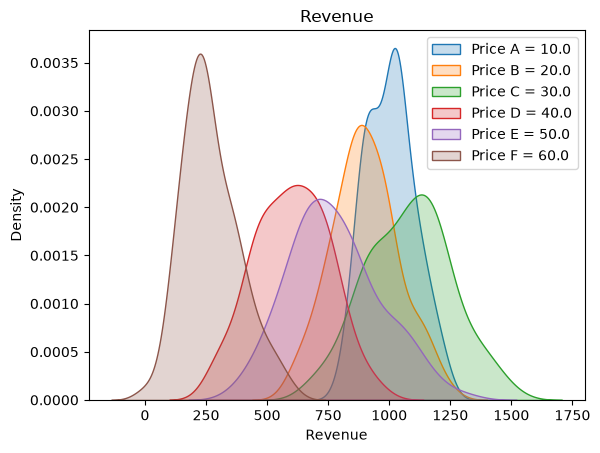

In [10]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 20.0
p_C = 30.0
p_D = 40.0
p_E = 50.0
p_F = 60.0
#p_G = 70.0
#p_H = 75.0

revenue_A = [ sales(p_A, rng=rng, mean_customers=100).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng, mean_customers=100).sum() * p_B for t in range(R) ]
revenue_C = [ sales(p_C, rng=rng, mean_customers=100).sum() * p_C for t in range(R) ]
revenue_D = [ sales(p_D, rng=rng, mean_customers=100).sum() * p_D for t in range(R) ]
revenue_E = [ sales(p_E, rng=rng, mean_customers=100).sum() * p_E for t in range(R) ]
revenue_F = [ sales(p_F, rng=rng, mean_customers=100).sum() * p_F for t in range(R) ]
#revenue_G = [ sales(p_G, rng=rng).sum() * p_G for t in range(R) ]
#revenue_H = [ sales(p_H, rng=rng).sum() * p_H for t in range(R) ]

sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
sns.kdeplot(revenue_C, fill=True, label=f"Price C = {p_C}")
sns.kdeplot(revenue_D, fill=True, label=f"Price D = {p_D}")
sns.kdeplot(revenue_E, fill=True, label=f"Price E = {p_E}")
sns.kdeplot(revenue_F, fill=True, label=f"Price F = {p_F}")
#sns.kdeplot(revenue_G, fill=True, label=f"Price G = {p_G}")
#sns.kdeplot(revenue_H, fill=True, label=f"Price H = {p_H}")

plt.legend()

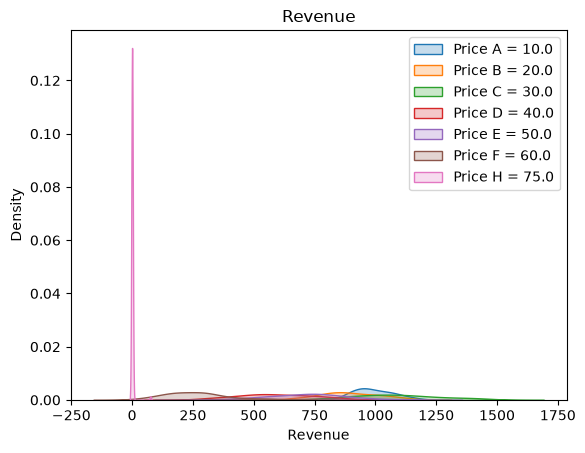

In [11]:
R = 100 # Test each price for 100 days
p_A = 10.0
p_B = 20.0
p_C = 30.0
p_D = 40.0
p_E = 50.0
p_F = 60.0
#p_G = 70.0
p_H = 75.0

revenue_A = [ sales(p_A, rng=rng, mean_customers=100).sum() * p_A for t in range(R) ]
revenue_B = [ sales(p_B, rng=rng, mean_customers=100).sum() * p_B for t in range(R) ]
revenue_C = [ sales(p_C, rng=rng, mean_customers=100).sum() * p_C for t in range(R) ]
revenue_D = [ sales(p_D, rng=rng, mean_customers=100).sum() * p_D for t in range(R) ]
revenue_E = [ sales(p_E, rng=rng, mean_customers=100).sum() * p_E for t in range(R) ]
revenue_F = [ sales(p_F, rng=rng, mean_customers=100).sum() * p_F for t in range(R) ]
#revenue_G = [ sales(p_G, rng=rng).sum() * p_G for t in range(R) ]
revenue_H = [ sales(p_H, rng=rng, mean_customers=100).sum() * p_H for t in range(R) ]

sns.kdeplot(revenue_A, fill=True, label=f"Price A = {p_A}").set(title=f"Revenue", xlabel="Revenue", ylabel="Density")
sns.kdeplot(revenue_B, fill=True, label=f"Price B = {p_B}")
sns.kdeplot(revenue_C, fill=True, label=f"Price C = {p_C}")
sns.kdeplot(revenue_D, fill=True, label=f"Price D = {p_D}")
sns.kdeplot(revenue_E, fill=True, label=f"Price E = {p_E}")
sns.kdeplot(revenue_F, fill=True, label=f"Price F = {p_F}")
#sns.kdeplot(revenue_G, fill=True, label=f"Price G = {p_G}")
sns.kdeplot(revenue_H, fill=True, label=f"Price H = {p_H}")

plt.legend()

In [12]:
gradient_ascent(start_price = 20, iterations=100, step=1.0, learning_rate=20.0, mean_customers=100, seed=100)

,iteration,price,gradient,gradient_se,ci_low,ci_high,customers,learning_rate,next_price
0,1,20.000000,0.468844,0.680051,-0.649840,1.587527,219,20.000000,22.000000
1,2,22.000000,1.022118,0.761711,-0.230896,2.275133,210,14.142136,24.000000
2,3,24.000000,-0.199939,0.848016,-1.594926,1.195047,199,11.547005,22.000000
3,4,22.000000,1.538549,0.772626,0.267580,2.809518,206,10.000000,24.000000
4,5,24.000000,0.803704,0.797473,-0.508140,2.115547,228,8.944272,26.000000
...,...,...,...,...,...,...,...,...,...
95,96,29.946173,-1.858740,0.971936,-3.457575,-0.259905,197,2.041241,27.946173
96,97,27.946173,-1.866495,1.017595,-3.540438,-0.192552,184,2.030692,25.946173
97,98,25.946173,0.727392,0.880652,-0.721281,2.176065,218,2.020305,27.415727
98,99,27.415727,0.107036,0.980554,-1.505976,1.720047,192,2.010076,27.630877


In [13]:
gradient_ascent(start_price = 20, iterations=100, step=1.0, learning_rate=20.0, mean_customers=100, seed=100)

,iteration,price,gradient,gradient_se,ci_low,ci_high,customers,learning_rate,next_price
0,1,20.000000,0.468844,0.680051,-0.649840,1.587527,219,20.000000,22.000000
1,2,22.000000,1.022118,0.761711,-0.230896,2.275133,210,14.142136,24.000000
2,3,24.000000,-0.199939,0.848016,-1.594926,1.195047,199,11.547005,22.000000
3,4,22.000000,1.538549,0.772626,0.267580,2.809518,206,10.000000,24.000000
4,5,24.000000,0.803704,0.797473,-0.508140,2.115547,228,8.944272,26.000000
...,...,...,...,...,...,...,...,...,...
95,96,29.946173,-1.858740,0.971936,-3.457575,-0.259905,197,2.041241,27.946173
96,97,27.946173,-1.866495,1.017595,-3.540438,-0.192552,184,2.030692,25.946173
97,98,25.946173,0.727392,0.880652,-0.721281,2.176065,218,2.020305,27.415727
98,99,27.415727,0.107036,0.980554,-1.505976,1.720047,192,2.010076,27.630877


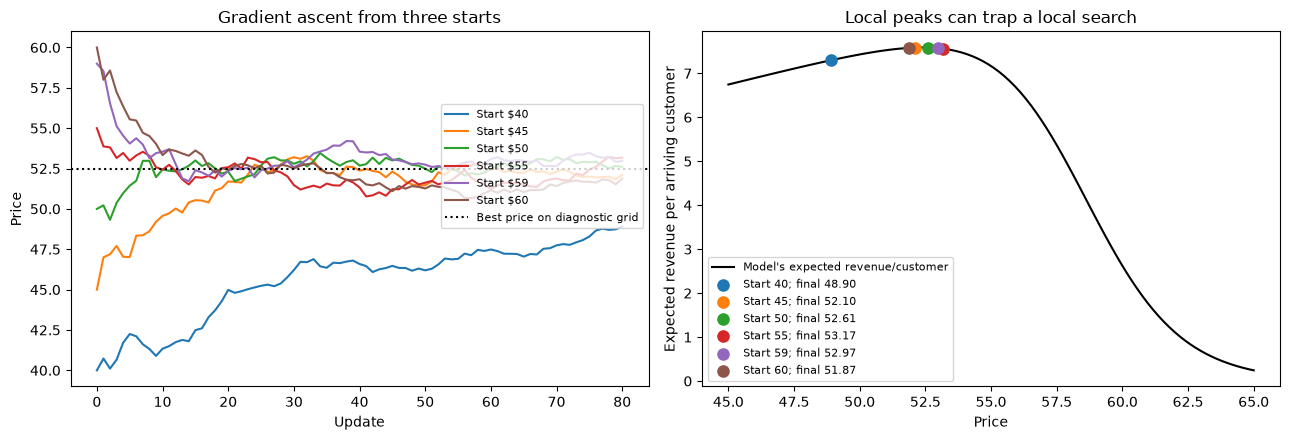

,start_price,final_price,search_customers,validation_customers,validation_revenue_per_customer,validation_se
0,40.0,48.902,48105,10036,7.260,0.174
1,45.0,52.100,47895,9894,7.683,0.186
2,50.0,52.611,47834,9826,7.341,0.184
3,55.0,53.173,48195,10105,7.798,0.187
4,59.0,52.973,47770,9800,7.551,0.187
5,60.0,51.869,47913,9875,7.453,0.183


In [14]:
# Only the diagnostic plot uses the model's true purchase curve.
# The search itself uses sales() at two nearby prices on every iteration.
starts = [40.0, 45.0, 50.0, 55.0, 59.0, 60.0]
ascent_paths = {
    start: gradient_ascent(start, seed=2026 + int(start))
    for start in starts
}
price_grid = np.linspace(45, 65, 100)
expected_revenue_per_customer = price_grid * purchase_probability(price_grid)
grid_best_price = price_grid[np.argmax(expected_revenue_per_customer)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[1].plot(price_grid, expected_revenue_per_customer,
             color="black", label="Model's expected revenue/customer")
evaluation_rng = np.random.default_rng(9001)
summary = []
for index, (start, history) in enumerate(ascent_paths.items()):
    color = f"C{index}"
    prices = np.r_[start, history["next_price"].to_numpy()]
    final_price = prices[-1]
    axes[0].plot(np.arange(len(prices)), prices,
                 color=color, label=f"Start ${start:g}")
    axes[1].scatter(final_price, final_price * purchase_probability(final_price),
                    color=color, s=65, zorder=3,
                    label=f"Start {start:g}; final {final_price:.2f}")

    # Evaluate the selected price with fresh customers, outside the search data.
    validation = final_price * sales(final_price, mean_customers=10_000,
                                      rng=evaluation_rng)
    summary.append({
        "start_price": start,
        "final_price": final_price,
        "search_customers": int(history["customers"].sum()),
        "validation_customers": len(validation),
        "validation_revenue_per_customer": validation.mean(),
        "validation_se": validation.std(ddof=1) / np.sqrt(len(validation)),
    })

axes[0].axhline(grid_best_price, color="black", linestyle=":",
                label="Best price on diagnostic grid")
axes[0].set(xlabel="Update", ylabel="Price", title="Gradient ascent from three starts")
axes[1].set(xlabel="Price", ylabel="Expected revenue per arriving customer",
            title="Local peaks can trap a local search")
axes[0].legend(loc="center right", bbox_to_anchor=(1, 0.62), fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

pd.DataFrame(summary).round(3)